# 03 · Prevendo cancelamentos (modelo preditivo e avaliação)

**Fases do CRISP-DM:** 4. Modelagem · 5. Avaliação · **Técnica:** Análise Preditiva

A pergunta do projeto é: *"Quais reservas têm alta chance de serem canceladas?"*

Este notebook responde: **dá para saber antes quem vai cancelar?**

**A ideia em uma frase:** o modelo aprende com **78 mil reservas de 2015–2016** quais
combinações de características costumam terminar em cancelamento e depois é testado nas
**reservas de 2017, que ele nunca viu**. É como estudar com as provas antigas e depois fazer
uma prova nova: só a prova nova mostra se ele aprendeu de verdade ou só decorou.

O resultado final é, para cada reserva, uma **chance de cancelamento** (de 0% a 100%) e uma
**faixa de risco**:

| Faixa | Chance de cancelar |
|---|---|
| Baixo | menos de 30% |
| Médio | de 30% a 60% |
| Alto | 60% ou mais |

**Roteiro do notebook**

- **Parte A — Modelagem (fase 4):** comparações de referência, três modelos, escolha do
  melhor e do "limiar de alerta", tudo só com os dados de 2015–2016.
- **Parte B — Avaliação (fase 5):** a prova final em 2017, faixas de risco, o que mais pesa
  no risco e se o modelo atinge o critério de sucesso.

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ / "src"))

from etl import SEED, carregar_dados_tratados
from visual import CORES, aplicar_estilo, salvar_figura, salvar_tabela

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
pd.set_option("display.max_columns", 40)


def br(numero, casas=0):
    # Formata um número no padrão brasileiro: 119.390 · 37,1.
    texto = f"{numero:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def pct(valor, casas=1):
    # 0.371 -> "37,1%"
    return f"{br(100 * valor, casas)}%"


def em_10(valor):
    # 0.712 -> "7 em cada 10"
    return f"{br(10 * valor, 0)} em cada 10"


from matplotlib.ticker import FuncFormatter

VIRGULA = FuncFormatter(lambda v, _: br(v, 2 if abs(v) < 0.1 and v != 0 else 1))


def euros_mi(valor, casas=1):
    return f"€ {br(valor / 1e6, casas)} mi"

## 1. Os dados e as regras do jogo

Usamos a base limpa preparada no ETL (notebook 01). Ela já vem separada em dois grupos
(decisão D2 da issue #1):

- **Treino:** chegadas até 31/12/2016. É com elas que o modelo aprende e com elas que fazemos
  **todas** as escolhas (qual modelo, a partir de que chance avisar).
- **Teste:** chegadas em 2017. Ficam **guardadas na gaveta** e só são usadas **uma vez, no
  fim**, como prova final. Assim imitamos a vida real: o hotel usaria o modelo em reservas
  futuras, que ninguém viu ainda.

In [3]:
base = carregar_dados_tratados()
treino = base[base["conjunto"] == "treino"].reset_index(drop=True)
teste = base[base["conjunto"] == "teste"].reset_index(drop=True)

print(f"Reservas no total: {br(len(base))}")
print(f"Treino (chegadas 2015–2016): {br(len(treino))} reservas · {pct(treino['cancelada'].mean())} canceladas")
print(f"Teste  (chegadas 2017):      {br(len(teste))} reservas · {pct(teste['cancelada'].mean())} canceladas")
print(f"Período do teste: {teste['data_chegada'].min():%d/%m/%Y} a {teste['data_chegada'].max():%d/%m/%Y}")

Reservas no total: 119.208
Treino (chegadas 2015–2016): 78.589 reservas · 36,2% canceladas
Teste  (chegadas 2017):      40.619 reservas · 38,7% canceladas
Período do teste: 01/01/2017 a 31/08/2017


### Quais informações o modelo pode usar

O modelo só pode usar o que **o hotel já sabe no momento da reserva**. Se usasse algo que só
aparece depois (por exemplo, a situação final da reserva), seria como **"colar na prova"**: ia
parecer ótimo no papel e não funcionaria na vida real.

Por isso a lista abaixo é fechada. Ficam de fora, de propósito:

- `cancelada`: é a resposta que queremos prever;
- `pais`: suspeita de ser preenchido só no check-in (decisão D5);
- `data_chegada` e `ano_chegada`: o "ano que vem" nunca aparece no aprendizado;
- `conjunto`: é só a etiqueta treino/teste;
- `receita_estimada`, `total_noites`, `total_hospedes`: repetem outras colunas.

In [4]:
NUMERICAS = [
    "antecedencia_dias", "mes_chegada", "semana_chegada", "noites_fim_semana", "noites_semana",
    "adultos", "criancas", "bebes", "hospede_recorrente", "cancelamentos_anteriores",
    "reservas_anteriores_nao_canceladas", "dias_lista_espera", "diaria_media",
    "vagas_estacionamento", "pedidos_especiais", "tem_agente", "tem_empresa",
]
CATEGORICAS = [
    "hotel", "regime_refeicao", "segmento_mercado", "canal_distribuicao",
    "tipo_quarto_reservado", "tipo_deposito", "tipo_cliente",
]
PROIBIDAS = [
    "cancelada", "pais", "data_chegada", "ano_chegada", "conjunto",
    "receita_estimada", "total_noites", "total_hospedes",
]
ATRIBUTOS = NUMERICAS + CATEGORICAS

# Conferência automática: nenhuma coluna proibida entrou na lista.
assert not set(ATRIBUTOS) & set(PROIBIDAS), "Coluna proibida na lista de atributos!"
assert set(ATRIBUTOS) | set(PROIBIDAS) == set(base.columns), "Alguma coluna ficou sem classificação"

print(f"O modelo usa {len(ATRIBUTOS)} informações de cada reserva:")
print("  Números:   ", ", ".join(NUMERICAS))
print("  Categorias:", ", ".join(CATEGORICAS))
print(f"Ficam de fora ({len(PROIBIDAS)}):", ", ".join(PROIBIDAS))

X_treino, y_treino = treino[ATRIBUTOS], treino["cancelada"]
X_teste, y_teste = teste[ATRIBUTOS], teste["cancelada"]

O modelo usa 24 informações de cada reserva:
  Números:    antecedencia_dias, mes_chegada, semana_chegada, noites_fim_semana, noites_semana, adultos, criancas, bebes, hospede_recorrente, cancelamentos_anteriores, reservas_anteriores_nao_canceladas, dias_lista_espera, diaria_media, vagas_estacionamento, pedidos_especiais, tem_agente, tem_empresa
  Categorias: hotel, regime_refeicao, segmento_mercado, canal_distribuicao, tipo_quarto_reservado, tipo_deposito, tipo_cliente
Ficam de fora (8): cancelada, pais, data_chegada, ano_chegada, conjunto, receita_estimada, total_noites, total_hospedes


# Parte A — Modelagem (fase 4 do CRISP-DM)

## 2. Comparações de referência: o modelo precisa vencer alguém

Antes de construir o modelo, definimos **com quem ele vai ser comparado**. Se ele não for
melhor que uma regra simples, não vale a pena usar.

1. **"Chute ingênuo":** dizer que **ninguém cancela**. Parece bobo, mas acerta muito, porque a
   maioria das reservas não cancela. Serve para mostrar por que o **"acerto geral" engana**.
2. **"Regra do gerente":** a regra que um gerente experiente usaria sem computador:
   *"cancela se a reserva foi feita com mais de 90 dias de antecedência **ou** com depósito não
   reembolsável"*.

### Como vamos dar nota (em frase de gerente)

| Nota | Nome técnico | O que significa para o hotel |
|---|---|---|
| Acerto geral | Acurácia | De cada 10 reservas, em quantas o palpite (cancela / não cancela) estava certo |
| Precisão | Precisão | De cada 10 reservas que foram marcadas como "vai cancelar", quantas cancelaram de fato |
| Cobertura | Recall (sensibilidade) | De cada 10 cancelamentos que aconteceram, quantos foram avisados antes |
| Nota F1 | F1 | Nota única que equilibra precisão e cobertura (de 0 a 1; quanto maior, melhor) |
| AUC | AUC | Chance de o modelo dar nota de risco maior a uma reserva que cancela do que a uma que não cancela (0,5 = sorteio; 1 = perfeito) |

In [5]:
def notas(y_real, y_previsto, probabilidade=None):
    # Calcula as notas de um conjunto de previsões.
    linha = {
        "acerto_geral": accuracy_score(y_real, y_previsto),
        "precisao": precision_score(y_real, y_previsto, zero_division=0),
        "cobertura_recall": recall_score(y_real, y_previsto, zero_division=0),
        "f1": f1_score(y_real, y_previsto, zero_division=0),
    }
    linha["auc"] = roc_auc_score(y_real, probabilidade) if probabilidade is not None else np.nan
    return linha


def chute_ingenuo(df):
    return np.zeros(len(df), dtype=int)


def regra_do_gerente(df):
    return ((df["antecedencia_dias"] > 90) | (df["tipo_deposito"] == "Não reembolsável")).astype(int).to_numpy()


ref_treino = pd.DataFrame(
    {
        "Chute ingênuo (ninguém cancela)": notas(y_treino, chute_ingenuo(treino)),
        "Regra do gerente": notas(y_treino, regra_do_gerente(treino)),
    }
).T
ref_treino.round(3)

,acerto_geral,precisao,cobertura_recall,f1,auc
Chute ingênuo (ninguém cancela),0.638,0.000,0.000,0.000,NaN
Regra do gerente,0.674,0.543,0.644,0.589,NaN


In [6]:
r = ref_treino.loc["Chute ingênuo (ninguém cancela)"]
g = ref_treino.loc["Regra do gerente"]
print(f"Chute ingênuo: acerta {em_10(r['acerto_geral'])} reservas, mas avisa 0 cancelamentos (cobertura {pct(r['cobertura_recall'], 0)}).")
print(f"Regra do gerente: avisa {em_10(g['cobertura_recall'])} cancelamentos, mas de cada 10 avisos só {br(10 * g['precisao'], 0)} cancelam de fato.")

Chute ingênuo: acerta 6 em cada 10 reservas, mas avisa 0 cancelamentos (cobertura 0%).
Regra do gerente: avisa 6 em cada 10 cancelamentos, mas de cada 10 avisos só 5 cancelam de fato.


**Leitura:** o "chute ingênuo" acerta cerca de 6 em cada 10 reservas e, mesmo assim, **não
serve para nada**: ele nunca avisa um cancelamento. É o exemplo perfeito de por que o
"acerto geral" engana quando a maioria das reservas não cancela. A partir daqui a nota que
importa é a **nota F1**, que só fica alta se o modelo **encontrar os cancelamentos** e
**não der alarme falso demais**.

A "regra do gerente" já ajuda: encontra boa parte dos cancelamentos, mas erra muito nos
avisos. **É essa regra que o modelo precisa superar.**

## 3. Três modelos candidatos

Testamos três tipos de modelo, do mais simples de explicar ao mais sofisticado:

| Modelo | Como funciona, em uma frase |
|---|---|
| **Regressão logística** | Dá um "peso" para cada característica e soma tudo numa nota de risco. É o mais fácil de explicar |
| **Floresta aleatória** | Cria 300 "árvores de perguntas" (ex.: *"antecedência > 90 dias? depósito não reembolsável?"*) e faz uma votação entre elas |
| **Gradient boosting** | Também usa árvores, mas cada nova árvore tenta corrigir os erros das anteriores |

Os três recebem as mesmas informações. As categorias (por exemplo, o segmento de mercado)
são transformadas em colunas de "sim/não", que é a forma como o computador consegue lê-las.

In [7]:
def preparador(padronizar_numeros):
    # Prepara as colunas para o modelo: categorias viram colunas sim/não; números
    # são colocados na mesma escala só para a regressão logística (que precisa disso).
    return ColumnTransformer(
        [
            ("numeros", StandardScaler() if padronizar_numeros else "passthrough", NUMERICAS),
            ("categorias", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
        ]
    )


MODELOS = {
    "Regressão logística": Pipeline(
        [("preparo", preparador(True)), ("modelo", LogisticRegression(max_iter=1000))]
    ),
    "Floresta aleatória": Pipeline(
        [
            ("preparo", preparador(False)),
            (
                "modelo",
                RandomForestClassifier(
                    n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED
                ),
            ),
        ]
    ),
    "Gradient boosting": Pipeline(
        [("preparo", preparador(False)), ("modelo", HistGradientBoostingClassifier(random_state=SEED))]
    ),
}

## 4. Validação cruzada: "simulados" dentro do treino

Para escolher o melhor modelo **sem espiar a prova final (2017)**, fazemos **simulados**
dentro do próprio treino: dividimos as reservas de 2015–2016 em 5 partes; o modelo estuda 4
partes e é testado na quinta; repetimos 5 vezes, trocando a parte de teste. A nota de cada
modelo é a média dos 5 simulados. Isso se chama **validação cruzada**.

Escolhemos o vencedor pela **nota F1**, porque ela premia quem encontra cancelamentos sem
encher o hotel de alarmes falsos.

In [8]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS_CV = {
    "acerto_geral": "accuracy",
    "precisao": "precision",
    "cobertura_recall": "recall",
    "f1": "f1",
    "auc": "roc_auc",
}

resultados_cv = {}
for nome, modelo in MODELOS.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=METRICAS_CV)
    resultados_cv[nome] = {m: r[f"test_{m}"].mean() for m in METRICAS_CV}
    resultados_cv[nome]["f1_variacao"] = r["test_f1"].std()
    print(f"{nome:<22} F1 = {br(resultados_cv[nome]['f1'], 3)} (± {br(resultados_cv[nome]['f1_variacao'], 3)})")

comparacao = pd.concat([ref_treino, pd.DataFrame(resultados_cv).T])
comparacao.index.name = "abordagem"
comparacao = comparacao.reset_index()
comparacao.round(3)

Regressão logística    F1 = 0,718 (± 0,004)


Floresta aleatória     F1 = 0,794 (± 0,002)


Gradient boosting      F1 = 0,782 (± 0,004)


,abordagem,acerto_geral,precisao,cobertura_recall,f1,auc,f1_variacao
0,Chute ingênuo (ninguém cancela),0.638,0.000,0.000,0.000,NaN,NaN
1,Regra do gerente,0.674,0.543,0.644,0.589,NaN,NaN
2,Regressão logística,0.828,0.883,0.604,0.718,0.858,0.004
3,Floresta aleatória,0.867,0.902,0.709,0.794,0.930,0.002
4,Gradient boosting,0.859,0.888,0.699,0.782,0.918,0.004


In [9]:
modelos_cv = comparacao[comparacao["abordagem"].isin(MODELOS)]
NOME_ESCOLHIDO = modelos_cv.sort_values("f1", ascending=False)["abordagem"].iloc[0]
escolhido_cv = modelos_cv.set_index("abordagem").loc[NOME_ESCOLHIDO]
print(f"Modelo escolhido: {NOME_ESCOLHIDO}")
print(f"  Nota F1 nos simulados: {br(escolhido_cv['f1'], 3)} (regra do gerente: {br(g['f1'], 3)})")
print(f"  Precisão: {em_10(escolhido_cv['precisao'])} avisos cancelam de fato")
print(f"  Cobertura: {em_10(escolhido_cv['cobertura_recall'])} cancelamentos são avisados")

Modelo escolhido: Floresta aleatória
  Nota F1 nos simulados: 0,794 (regra do gerente: 0,589)
  Precisão: 9 em cada 10 avisos cancelam de fato
  Cobertura: 7 em cada 10 cancelamentos são avisados


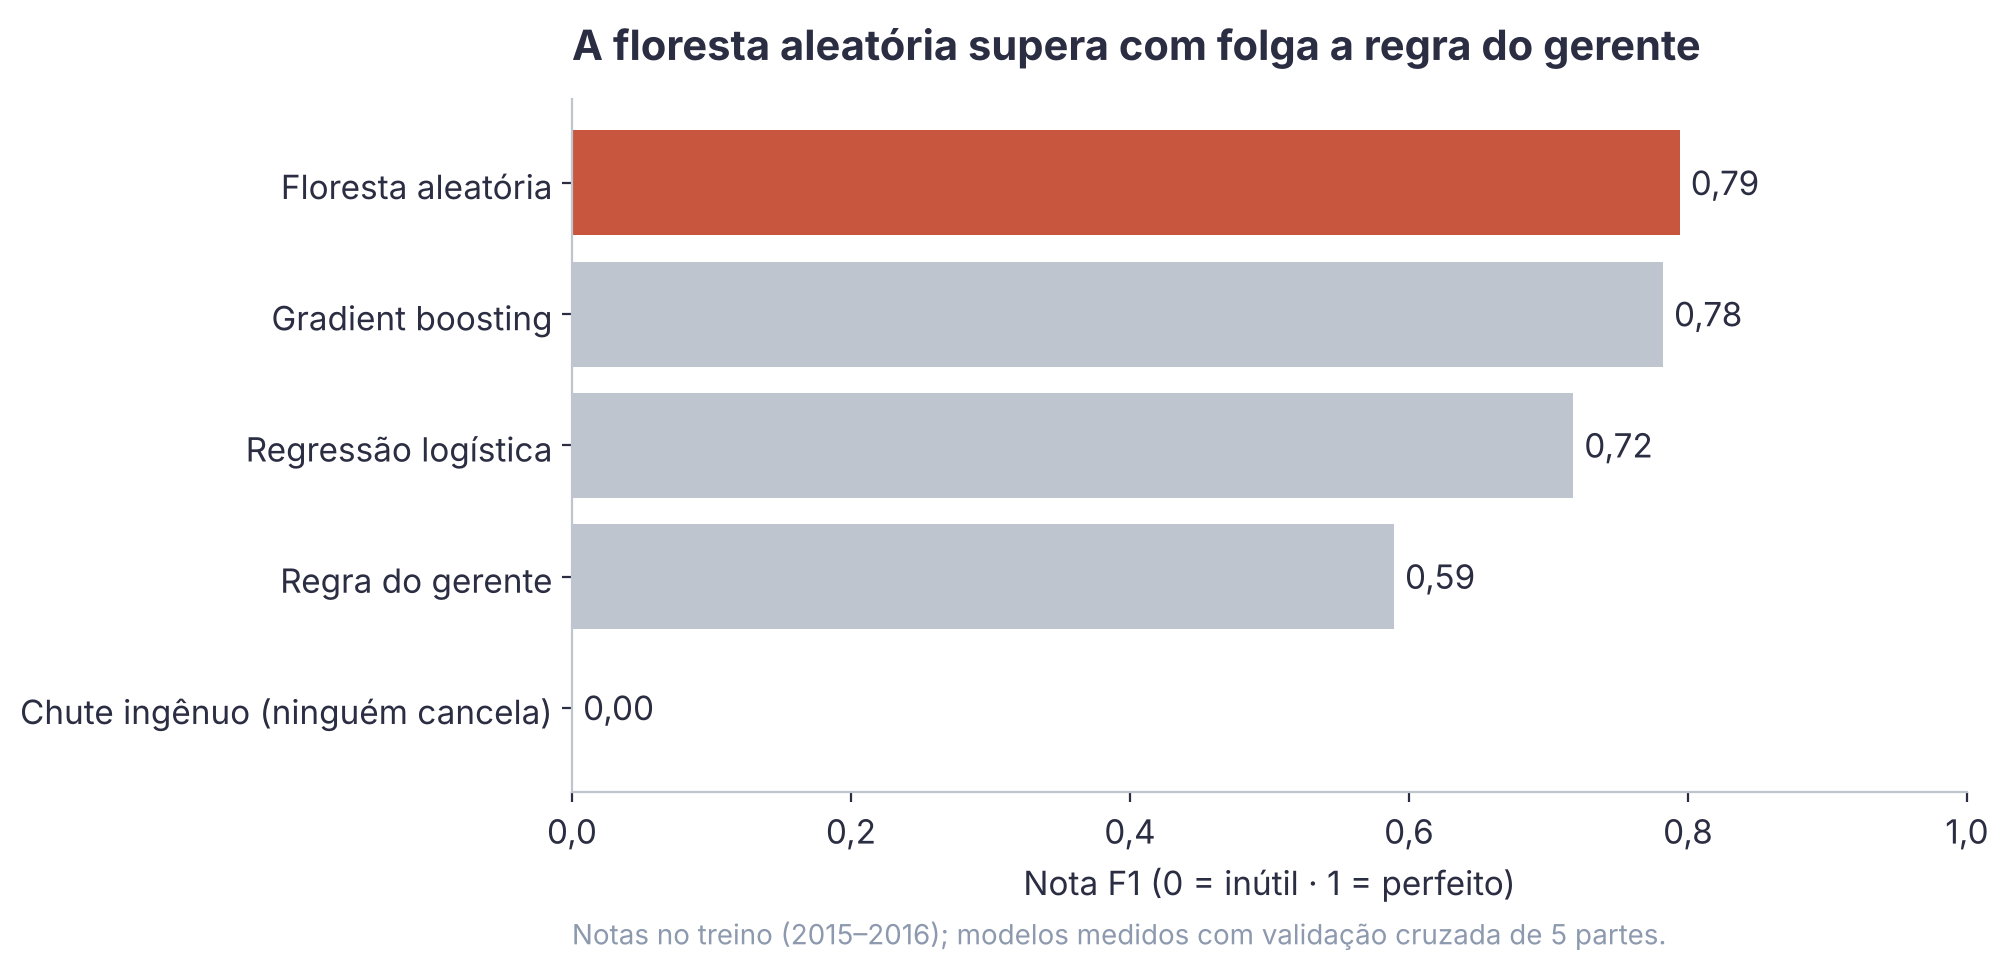

In [10]:
tabela_comp = comparacao.copy()
tabela_comp["etapa"] = "validação cruzada no treino (2015–2016)"
tabela_comp.loc[tabela_comp["abordagem"].isin(ref_treino.index), "etapa"] = "regra aplicada ao treino (2015–2016)"
tabela_comp["escolhido"] = tabela_comp["abordagem"] == NOME_ESCOLHIDO
salvar_tabela(tabela_comp.round(4), "03_comparacao_modelos")

ordem = comparacao.sort_values("f1")
cores = [CORES["destaque"] if n == NOME_ESCOLHIDO else CORES["neutro"] for n in ordem["abordagem"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(ordem["abordagem"], ordem["f1"], color=cores)
ax.bar_label(barras, labels=[br(v, 2) for v in ordem["f1"]], padding=4)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(VIRGULA)
ax.set_xlabel("Nota F1 (0 = inútil · 1 = perfeito)")
ax.set_title(f"A {NOME_ESCOLHIDO.lower()} supera com folga a regra do gerente")
ax.text(0, -0.22, "Notas no treino (2015–2016); modelos medidos com validação cruzada de 5 partes.",
        transform=ax.transAxes, fontsize=10, color=CORES["veio"])
salvar_figura(fig, "03_comparacao_modelos")
plt.show()

**Por que este modelo:** a floresta aleatória teve a **maior nota F1** nos simulados e também
a maior AUC. A regressão logística, embora mais simples de explicar, deixa escapar muito mais
cancelamentos. O gradient boosting chega perto, mas fica um pouco atrás. Como a diferença de
nota entre os 5 simulados é pequena (o "±"), a vitória não foi sorte de uma divisão.

> Nota honesta: o modelo vencedor é uma "caixa mais escura" do que a regressão logística. Para
> compensar, na Parte B mostramos **quais informações mais pesam** no risco que ele calcula.

## 5. Limiar de alerta: a partir de que chance o hotel deve ser avisado?

O modelo não diz só "sim" ou "não"; ele dá uma **chance de cancelamento** para cada reserva.
O hotel precisa decidir **a partir de que chance quer ser avisado**:

- limiar **baixo** (ex.: 20%) → avisa quase todos os cancelamentos, mas com muito alarme falso;
- limiar **alto** (ex.: 80%) → quase todo aviso é certeiro, mas muitos cancelamentos escapam.

Escolhemos o limiar que dá a **melhor nota F1**, usando de novo só o treino: cada reserva de
2015–2016 recebe a chance calculada por um modelo que **não a viu** durante o estudo (as
"previsões fora da dobra" da validação cruzada).

In [11]:
modelo_escolhido = MODELOS[NOME_ESCOLHIDO]
prob_fora_dobra = cross_val_predict(
    modelo_escolhido, X_treino, y_treino, cv=validacao, method="predict_proba"
)[:, 1]

precisoes, coberturas, limiares = precision_recall_curve(y_treino, prob_fora_dobra)
f1s = 2 * precisoes * coberturas / np.clip(precisoes + coberturas, 1e-12, None)
melhor = int(np.nanargmax(f1s[:-1]))
LIMIAR = float(limiares[melhor])

print(f"Limiar de alerta escolhido: {pct(LIMIAR)} de chance de cancelar")
print(f"  No treino, com esse limiar: F1 = {br(f1s[melhor], 3)} · "
      f"precisão {pct(precisoes[melhor])} · cobertura {pct(coberturas[melhor])}")
print(f"  Com o limiar padrão de 50%: F1 = {br(f1_score(y_treino, prob_fora_dobra >= 0.5), 3)}")

Limiar de alerta escolhido: 37,1% de chance de cancelar
  No treino, com esse limiar: F1 = 0,811 · precisão 83,6% · cobertura 78,8%
  Com o limiar padrão de 50%: F1 = 0,794


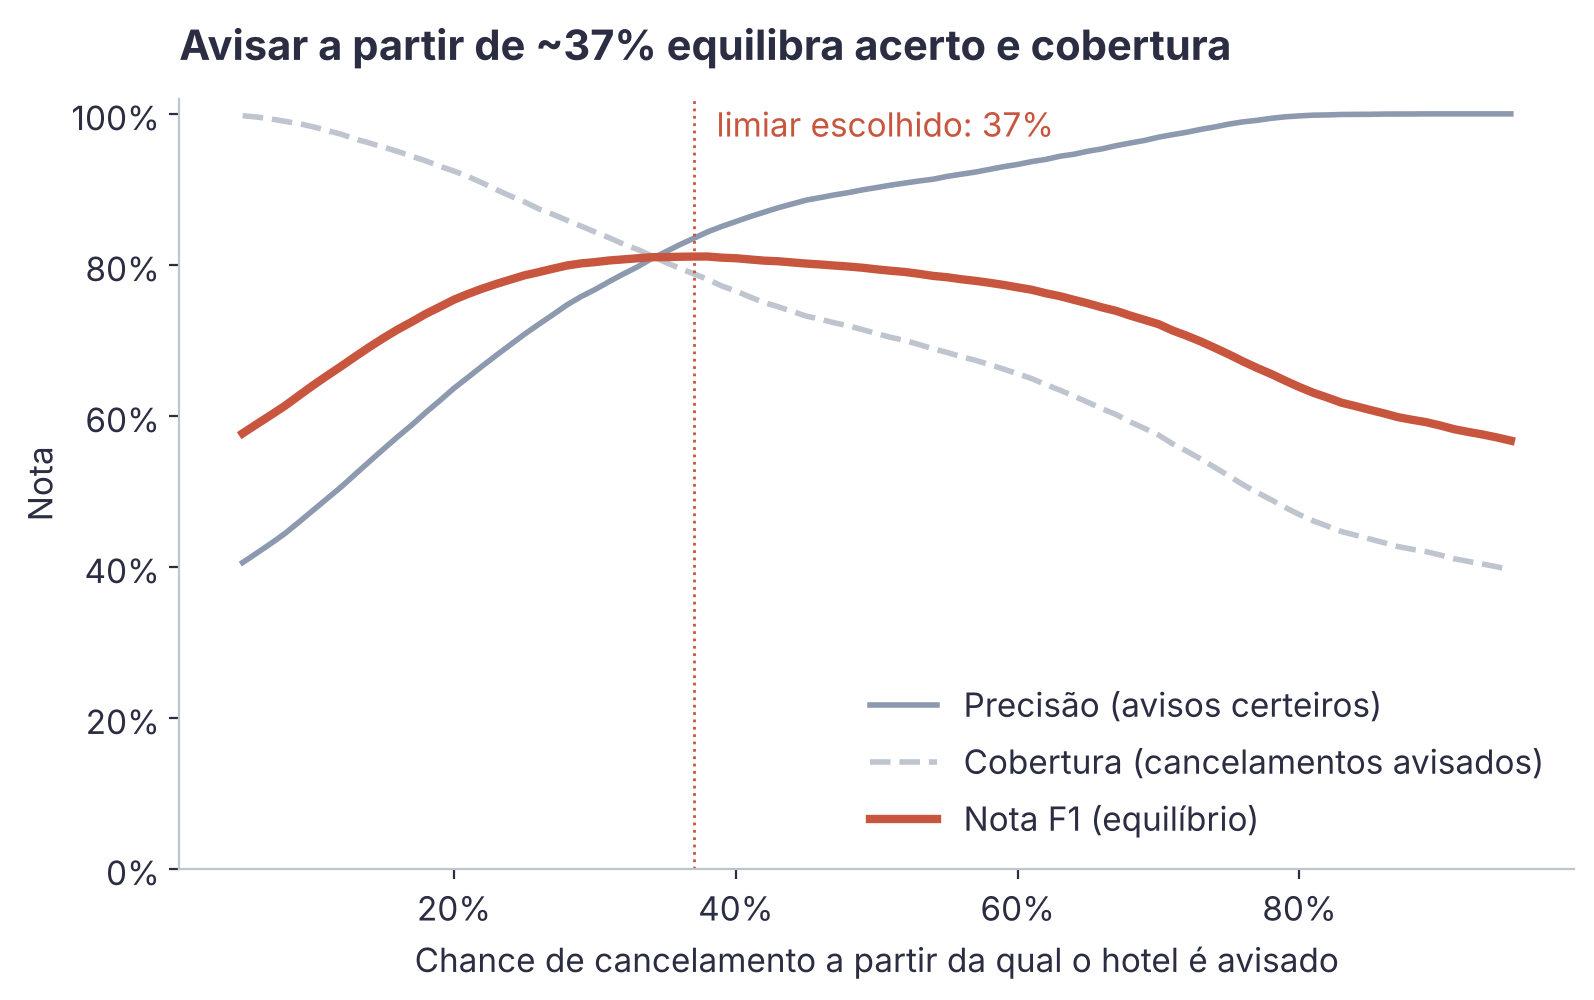

In [12]:
grade = np.arange(0.05, 0.96, 0.01)
curva = pd.DataFrame(
    {
        "limiar": grade,
        "precisao": [precision_score(y_treino, prob_fora_dobra >= t, zero_division=0) for t in grade],
        "cobertura": [recall_score(y_treino, prob_fora_dobra >= t) for t in grade],
        "f1": [f1_score(y_treino, prob_fora_dobra >= t) for t in grade],
    }
)
fig, ax = plt.subplots()
ax.plot(curva["limiar"], curva["precisao"], color=CORES["veio"], lw=2, label="Precisão (avisos certeiros)")
ax.plot(curva["limiar"], curva["cobertura"], color=CORES["neutro"], lw=2, ls="--", label="Cobertura (cancelamentos avisados)")
ax.plot(curva["limiar"], curva["f1"], color=CORES["destaque"], lw=3, label="Nota F1 (equilíbrio)")
ax.axvline(LIMIAR, color=CORES["destaque"], lw=1, ls=":")
ax.annotate(f"limiar escolhido: {pct(LIMIAR, 0)}", (LIMIAR, 0.97), xytext=(8, 0),
            textcoords="offset points", color=CORES["destaque"])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Chance de cancelamento a partir da qual o hotel é avisado")
ax.set_ylabel("Nota")
ax.set_ylim(0, 1.02)
ax.set_title("Avisar a partir de ~" + pct(LIMIAR, 0) + " equilibra acerto e cobertura")
ax.legend(loc="lower right")
salvar_figura(fig, "03_limiar_de_alerta")
plt.show()

**Leitura:** o limiar é o "volume do alarme". Mais baixo, o alarme toca mais e pega mais
cancelamentos, mas também toca à toa; mais alto, só toca quando é quase certeza. O ponto
escolhido é o que equilibra os dois lados no treino. Ele será usado na prova final **sem
nenhum ajuste**.

**Limiar × faixas de risco:** o limiar responde *"essa reserva entra na lista de aviso?"*. As
**faixas de risco** (baixo / médio / alto, decisão D6) são fixas e servem para **resumir** o
risco de cada reserva. As duas coisas aparecem na avaliação.

# Parte B — Avaliação (fase 5 do CRISP-DM)

## 6. A prova final: reservas de 2017

Agora, e **só agora**, tiramos as reservas de 2017 da gaveta. O modelo escolhido estuda
**todas** as reservas de 2015–2016 e dá uma chance de cancelamento para cada reserva de 2017.
Esta é a única vez que o teste é usado.

In [13]:
modelo_escolhido.fit(X_treino, y_treino)
prob_teste = modelo_escolhido.predict_proba(X_teste)[:, 1]
aviso_teste = (prob_teste >= LIMIAR).astype(int)

resultado_teste = pd.DataFrame(
    {
        "Chute ingênuo (ninguém cancela)": notas(y_teste, chute_ingenuo(teste)),
        "Regra do gerente": notas(y_teste, regra_do_gerente(teste)),
        NOME_ESCOLHIDO: notas(y_teste, aviso_teste, prob_teste),
    }
).T
resultado_teste.round(3)

,acerto_geral,precisao,cobertura_recall,f1,auc
Chute ingênuo (ninguém cancela),0.613,0.000,0.000,0.000,NaN
Regra do gerente,0.631,0.518,0.669,0.584,NaN
Floresta aleatória,0.768,0.740,0.617,0.673,0.84


In [14]:
m = resultado_teste.loc[NOME_ESCOLHIDO]
rg = resultado_teste.loc["Regra do gerente"]
print(f"Em 2017, com o limiar de {pct(LIMIAR, 0)}:")
print(f"  Precisão:  de cada 10 reservas que o modelo marcou como 'vai cancelar', {br(10 * m['precisao'], 0)} cancelaram de fato "
      f"(regra do gerente: {br(10 * rg['precisao'], 0)}).")
print(f"  Cobertura: de cada 10 cancelamentos que aconteceram, o modelo avisou {br(10 * m['cobertura_recall'], 0)} antes "
      f"(regra do gerente: {br(10 * rg['cobertura_recall'], 0)}).")
print(f"  Nota F1:   {br(m['f1'], 2)} (regra do gerente: {br(rg['f1'], 2)}).")
print(f"  AUC:       {br(m['auc'], 2)}: se pegarmos ao acaso uma reserva que cancelou e uma que não cancelou, "
      f"em {br(100 * m['auc'], 0)}% das vezes o modelo dá risco maior para a que cancelou.")

Em 2017, com o limiar de 37%:
  Precisão:  de cada 10 reservas que o modelo marcou como 'vai cancelar', 7 cancelaram de fato (regra do gerente: 5).
  Cobertura: de cada 10 cancelamentos que aconteceram, o modelo avisou 6 antes (regra do gerente: 7).
  Nota F1:   0,67 (regra do gerente: 0,58).
  AUC:       0,84: se pegarmos ao acaso uma reserva que cancelou e uma que não cancelou, em 84% das vezes o modelo dá risco maior para a que cancelou.


### O quadro dos 4 resultados (matriz de confusão)

Cada reserva de 2017 cai em um de quatro quadrados, conforme o modelo avisou ou não e o
hóspede cancelou ou veio:

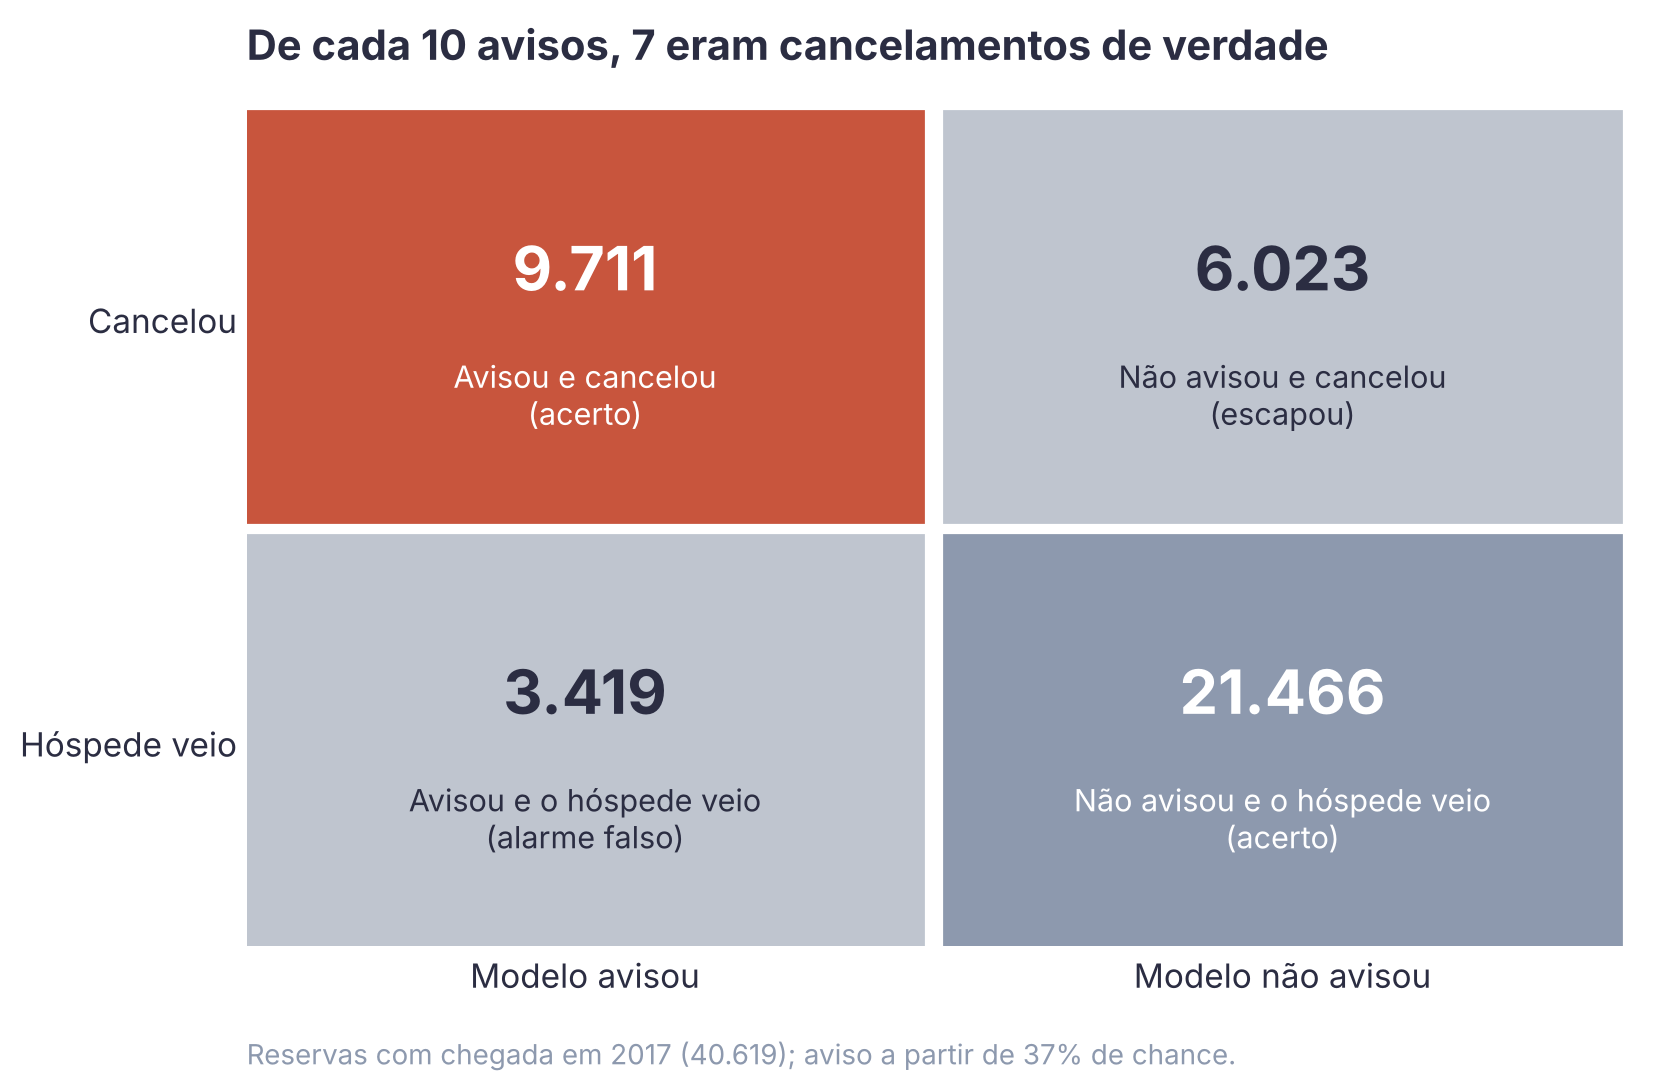

Avisou e cancelou: 9.711 · Alarme falso: 3.419 · Escapou: 6.023 · Não avisou e veio: 21.466


In [15]:
vn, fp, fn, vp = confusion_matrix(y_teste, aviso_teste).ravel()
quadro = np.array([[vp, fn], [fp, vn]])
rotulos = np.array(
    [
        ["Avisou e cancelou\n(acerto)", "Não avisou e cancelou\n(escapou)"],
        ["Avisou e o hóspede veio\n(alarme falso)", "Não avisou e o hóspede veio\n(acerto)"],
    ]
)
cores_quadro = np.array([[CORES["destaque"], CORES["neutro"]], [CORES["neutro"], CORES["veio"]]])

fig, ax = plt.subplots(figsize=(9, 5.5))
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 0.97, 0.97, color=cores_quadro[i, j]))
        cor_texto = "white" if cores_quadro[i, j] != CORES["neutro"] else CORES["texto"]
        ax.text(j + 0.485, 1 - i + 0.6, br(quadro[i, j]), ha="center", va="center",
                fontsize=22, fontweight="bold", color=cor_texto)
        ax.text(j + 0.485, 1 - i + 0.3, rotulos[i, j], ha="center", va="center",
                fontsize=11, color=cor_texto)
ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.485, 1.485], ["Modelo avisou", "Modelo não avisou"])
ax.set_yticks([1.485, 0.485], ["Cancelou", "Hóspede veio"])
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title(f"De cada 10 avisos, {br(10 * vp / (vp + fp), 0)} eram cancelamentos de verdade")
ax.text(0, -0.14, f"Reservas com chegada em 2017 ({br(len(teste))}); aviso a partir de {pct(LIMIAR, 0)} de chance.",
        transform=ax.transAxes, fontsize=10, color=CORES["veio"])
salvar_figura(fig, "03_matriz_confusao")
plt.show()

print(f"Avisou e cancelou: {br(vp)} · Alarme falso: {br(fp)} · Escapou: {br(fn)} · Não avisou e veio: {br(vn)}")

## 7. Faixas de risco: o gráfico principal

Para a equipe do hotel, o que importa é: **em que reservas eu concentro o esforço?** Cada
reserva de 2017 vai para uma faixa, conforme a chance que o modelo calculou (decisão D6):
**baixo** (menos de 30%), **médio** (30% a 60%) e **alto** (60% ou mais).

Se o modelo for bom, a **taxa real de cancelamento** tem que subir muito de uma faixa para a
outra.

In [16]:
FAIXAS = ["Baixo", "Médio", "Alto"]


def faixa_de_risco(probabilidade):
    return pd.Categorical(
        pd.cut(probabilidade, bins=[-0.001, 0.30, 0.60, 1.001], right=False, labels=FAIXAS),
        categories=FAIXAS,
        ordered=True,
    )


teste_risco = teste.copy()
teste_risco["probabilidade_cancelamento"] = prob_teste.round(3)
# A faixa é calculada sobre a chance já arredondada, para bater com o arquivo entregue ao #5.
teste_risco["faixa_risco"] = faixa_de_risco(teste_risco["probabilidade_cancelamento"])

faixas = (
    teste_risco.groupby("faixa_risco", observed=False)
    .agg(
        reservas=("cancelada", "size"),
        cancelamentos=("cancelada", "sum"),
        receita_estimada=("receita_estimada", "sum"),
    )
    .reset_index()
)
faixas["pct_das_reservas"] = faixas["reservas"] / faixas["reservas"].sum()
faixas["taxa_real_cancelamento"] = faixas["cancelamentos"] / faixas["reservas"]
receita_cancelada = (
    teste_risco[teste_risco["cancelada"] == 1]
    .groupby("faixa_risco", observed=False)["receita_estimada"].sum()
)
faixas["receita_das_canceladas"] = faixas["faixa_risco"].map(receita_cancelada).astype(float)
faixas["pct_dos_cancelamentos"] = faixas["cancelamentos"] / faixas["cancelamentos"].sum()
faixas = faixas[
    ["faixa_risco", "reservas", "pct_das_reservas", "cancelamentos", "taxa_real_cancelamento",
     "pct_dos_cancelamentos", "receita_estimada", "receita_das_canceladas"]
]
salvar_tabela(faixas.round(4), "03_faixas_de_risco")
faixas.round(3)

,faixa_risco,reservas,pct_das_reservas,cancelamentos,taxa_real_cancelamento,pct_dos_cancelamentos,receita_estimada,receita_das_canceladas
0,Baixo,24452,0.602,4615,0.189,0.293,9245985.02,1947783.73
1,Médio,6795,0.167,3508,0.516,0.223,3563031.22,1933878.45
2,Alto,9372,0.231,7611,0.812,0.484,4223293.30,3341917.72


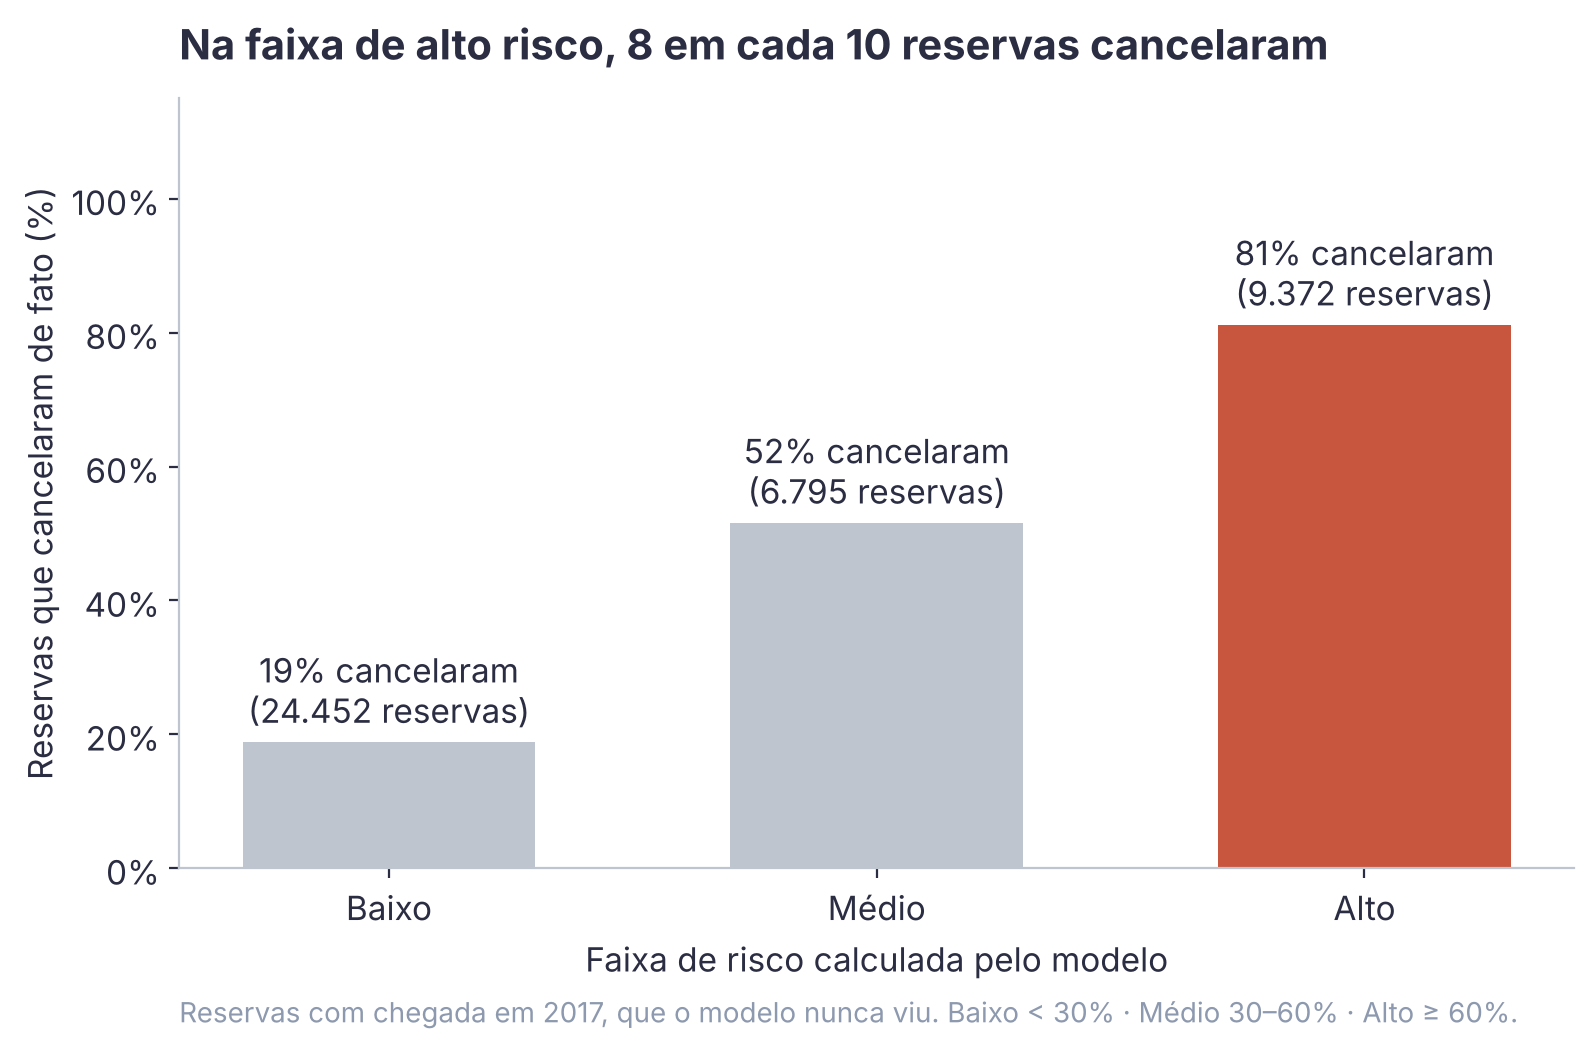

Baixo   60% das reservas ·  19% cancelaram · 29% de todos os cancelamentos · receita das canceladas € 1,9 mi
Médio   17% das reservas ·  52% cancelaram · 22% de todos os cancelamentos · receita das canceladas € 1,9 mi
Alto    23% das reservas ·  81% cancelaram · 48% de todos os cancelamentos · receita das canceladas € 3,3 mi


In [17]:
fig, ax = plt.subplots()
cores = [CORES["neutro"], CORES["neutro"], CORES["destaque"]]
barras = ax.bar(faixas["faixa_risco"].astype(str), faixas["taxa_real_cancelamento"], color=cores, width=0.6)
ax.bar_label(
    barras,
    labels=[f"{pct(t, 0)} cancelaram\n({br(n)} reservas)" for t, n in zip(faixas["taxa_real_cancelamento"], faixas["reservas"])],
    padding=4,
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.15)
ax.set_ylabel("Reservas que cancelaram de fato (%)")
ax.set_xlabel("Faixa de risco calculada pelo modelo")
alto = faixas.set_index("faixa_risco").loc["Alto"]
ax.set_title(f"Na faixa de alto risco, {em_10(alto['taxa_real_cancelamento'])} reservas cancelaram")
ax.text(0, -0.2, "Reservas com chegada em 2017, que o modelo nunca viu. Baixo < 30% · Médio 30–60% · Alto ≥ 60%.",
        transform=ax.transAxes, fontsize=10, color=CORES["veio"])
salvar_figura(fig, "03_faixas_de_risco")
plt.show()

for _, f in faixas.iterrows():
    print(f"{f['faixa_risco']:<6} {pct(f['pct_das_reservas'], 0):>4} das reservas · {pct(f['taxa_real_cancelamento'], 0):>4} cancelaram · "
          f"{pct(f['pct_dos_cancelamentos'], 0)} de todos os cancelamentos · receita das canceladas {euros_mi(f['receita_das_canceladas'])}")

**Leitura:** as faixas separam bem as reservas. Na faixa **baixa**, cerca de 8 em cada 10
hóspedes vêm; na faixa **alta**, cerca de 8 em cada 10 reservas cancelam. A faixa alta reúne
**menos de 1 em cada 4 reservas**, mas **quase metade de todos os cancelamentos**: a equipe pode
concentrar o esforço num grupo pequeno e encontrar ali boa parte do problema. A faixa média é
a "zona cinzenta" (metade cancela, metade vem).

## 8. O que mais pesa no risco

Para abrir a "caixa" do modelo, usamos um teste simples: **embaralhamos uma informação de
cada vez** (por exemplo, trocamos a antecedência de todas as reservas entre si, ao acaso) e
vemos **quanto o modelo piora**. Se piorar muito, aquela informação é importante; se não mudar
nada, ela não faz diferença. O nome técnico é **importância por permutação**.

Para rodar rápido, fazemos isso numa amostra de 10.000 reservas de 2017, repetindo 5 vezes. A
"piora" é medida na AUC (a capacidade de ordenar quem tem mais risco).

In [18]:
amostra = teste.sample(n=10_000, random_state=SEED)
importancia = permutation_importance(
    modelo_escolhido,
    amostra[ATRIBUTOS],
    amostra["cancelada"],
    scoring="roc_auc",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1,
)
fatores = (
    pd.DataFrame(
        {
            "fator": ATRIBUTOS,
            "piora_media_auc": importancia.importances_mean,
            "variacao": importancia.importances_std,
        }
    )
    .sort_values("piora_media_auc", ascending=False)
    .reset_index(drop=True)
)
fatores.head(12).round(4)

,fator,piora_media_auc,variacao
0,tipo_deposito,0.1090,0.0024
1,pedidos_especiais,0.0532,0.0012
2,antecedencia_dias,0.0481,0.0031
3,segmento_mercado,0.0426,0.0012
4,tipo_cliente,0.0310,0.0019
5,vagas_estacionamento,0.0258,0.0019
6,diaria_media,0.0103,0.0007
7,hotel,0.0083,0.0008
8,canal_distribuicao,0.0044,0.0005
9,adultos,0.0040,0.0002


In [19]:
# Uma frase de gerente para cada fator, comprovada com a taxa de cancelamento no treino.
def taxa(mascara):
    return treino.loc[mascara, "cancelada"].mean()


def frase_fator(fator):
    t = treino
    if fator == "antecedencia_dias":
        return (f"Quanto mais cedo a reserva é feita, mais ela cancela: {pct(taxa(t[fator] > 180), 0)} das feitas com mais de "
                f"6 meses cancelam, contra {pct(taxa(t[fator] <= 7), 0)} das feitas na mesma semana.")
    if fator == "tipo_deposito":
        return (f"Reservas 'não reembolsáveis' cancelam {pct(taxa(t[fator] == 'Não reembolsável'), 0)} das vezes "
                f"(contra {pct(taxa(t[fator] == 'Sem depósito'), 0)} sem depósito). É um padrão estranho, para o hotel investigar.")
    if fator == "pedidos_especiais":
        return (f"Quem faz pedidos especiais está comprometido com a viagem: {pct(taxa(t[fator] >= 1), 0)} cancelam, "
                f"contra {pct(taxa(t[fator] == 0), 0)} de quem não faz nenhum pedido.")
    if fator == "segmento_mercado":
        return (f"O canal de origem importa: reservas de agência online cancelam {pct(taxa(t[fator] == 'Agência online'), 0)}, "
                f"de grupos {pct(taxa(t[fator] == 'Grupos'), 0)} e diretas {pct(taxa(t[fator] == 'Direto'), 0)}.")
    if fator == "vagas_estacionamento":
        return (f"Quem pede vaga de garagem praticamente sempre vem: {pct(taxa(t[fator] >= 1), 0)} cancelam, "
                f"contra {pct(taxa(t[fator] == 0), 0)} de quem não pede.")
    if fator == "cancelamentos_anteriores":
        return (f"Quem já cancelou antes tende a cancelar de novo: {pct(taxa(t[fator] >= 1), 0)} cancelam, "
                f"contra {pct(taxa(t[fator] == 0), 0)} de quem nunca cancelou.")
    if fator == "diaria_media":
        return ("Sozinho, o valor da diária não separa quem cancela; combinado com hotel, época e canal, "
                "ajuda o modelo a reconhecer perfis de reserva.")
    if fator == "tipo_cliente":
        return (f"O tipo de reserva pesa: avulsas cancelam {pct(taxa(t[fator] == 'Avulso'), 0)}, "
                f"avulsas ligadas a outra reserva {pct(taxa(t[fator] == 'Avulso ligado a outra reserva'), 0)}.")
    if fator == "hotel":
        return (f"O hotel de cidade cancela mais ({pct(taxa(t[fator] == 'Hotel de cidade'), 0)}) "
                f"que o resort ({pct(taxa(t[fator] == 'Resort'), 0)}).")
    if fator == "tem_agente":
        return (f"Reservas feitas por agência de viagens cancelam {pct(taxa(t[fator] == 1), 0)}, "
                f"contra {pct(taxa(t[fator] == 0), 0)} das demais.")
    if fator == "canal_distribuicao":
        return (f"Pelo canal de agência/operadora cancelam {pct(taxa(t[fator] == 'Agência/operadora'), 0)}; "
                f"pelo canal direto, {pct(taxa(t[fator] == 'Direto'), 0)}.")
    if fator == "reservas_anteriores_nao_canceladas":
        return (f"Quem já cumpriu reservas antes quase não cancela: {pct(taxa(t[fator] >= 1), 0)}, "
                f"contra {pct(taxa(t[fator] == 0), 0)} dos demais.")
    if fator in ("semana_chegada", "mes_chegada"):
        return "A época da chegada muda o risco (alta temporada, feriados, eventos na cidade)."
    if fator in ("noites_semana", "noites_fim_semana"):
        return "A duração e o tipo de estadia (dias úteis × fim de semana) ajudam a diferenciar viagens de lazer e de trabalho."
    if fator == "tipo_quarto_reservado":
        return "O tipo de quarto pedido ajuda a diferenciar perfis de hóspede."
    if fator == "regime_refeicao":
        return "O que está incluído na diária (café, meia pensão...) ajuda a diferenciar perfis de hóspede."
    return "Ajuda o modelo a diferenciar perfis de reserva."


NOMES_FATOR = {
    "antecedencia_dias": "Antecedência da reserva", "tipo_deposito": "Tipo de depósito",
    "pedidos_especiais": "Pedidos especiais", "segmento_mercado": "Segmento de mercado",
    "vagas_estacionamento": "Vaga de garagem", "cancelamentos_anteriores": "Cancelamentos anteriores",
    "diaria_media": "Valor da diária", "tipo_cliente": "Tipo de cliente", "hotel": "Hotel",
    "tem_agente": "Reserva por agência", "canal_distribuicao": "Canal de venda",
    "reservas_anteriores_nao_canceladas": "Reservas anteriores cumpridas",
    "semana_chegada": "Semana da chegada", "mes_chegada": "Mês da chegada",
    "noites_semana": "Noites em dias úteis", "noites_fim_semana": "Noites de fim de semana",
    "tipo_quarto_reservado": "Tipo de quarto", "regime_refeicao": "Regime de refeição",
    "adultos": "Número de adultos", "criancas": "Número de crianças", "bebes": "Número de bebês",
    "hospede_recorrente": "Hóspede que já veio antes", "dias_lista_espera": "Dias na lista de espera",
    "tem_empresa": "Reserva por empresa",
}

top8 = fatores.head(8).copy()
top8.insert(0, "posicao", range(1, 9))
top8.insert(2, "nome", top8["fator"].map(NOMES_FATOR))
top8["explicacao"] = top8["fator"].map(frase_fator)
salvar_tabela(top8.round(4), "03_fatores_de_risco")
for _, f in top8.iterrows():
    print(f"{f['posicao']}. {f['nome']}: {f['explicacao']}")

1. Tipo de depósito: Reservas 'não reembolsáveis' cancelam 99% das vezes (contra 27% sem depósito). É um padrão estranho, para o hotel investigar.
2. Pedidos especiais: Quem faz pedidos especiais está comprometido com a viagem: 19% cancelam, contra 47% de quem não faz nenhum pedido.
3. Antecedência da reserva: Quanto mais cedo a reserva é feita, mais ela cancela: 60% das feitas com mais de 6 meses cancelam, contra 10% das feitas na mesma semana.
4. Segmento de mercado: O canal de origem importa: reservas de agência online cancelam 34%, de grupos 62% e diretas 15%.
5. Tipo de cliente: O tipo de reserva pesa: avulsas cancelam 39%, avulsas ligadas a outra reserva 28%.
6. Vaga de garagem: Quem pede vaga de garagem praticamente sempre vem: 0% cancelam, contra 39% de quem não pede.
7. Valor da diária: Sozinho, o valor da diária não separa quem cancela; combinado com hotel, época e canal, ajuda o modelo a reconhecer perfis de reserva.
8. Hotel: O hotel de cidade cancela mais (41%) que o resor

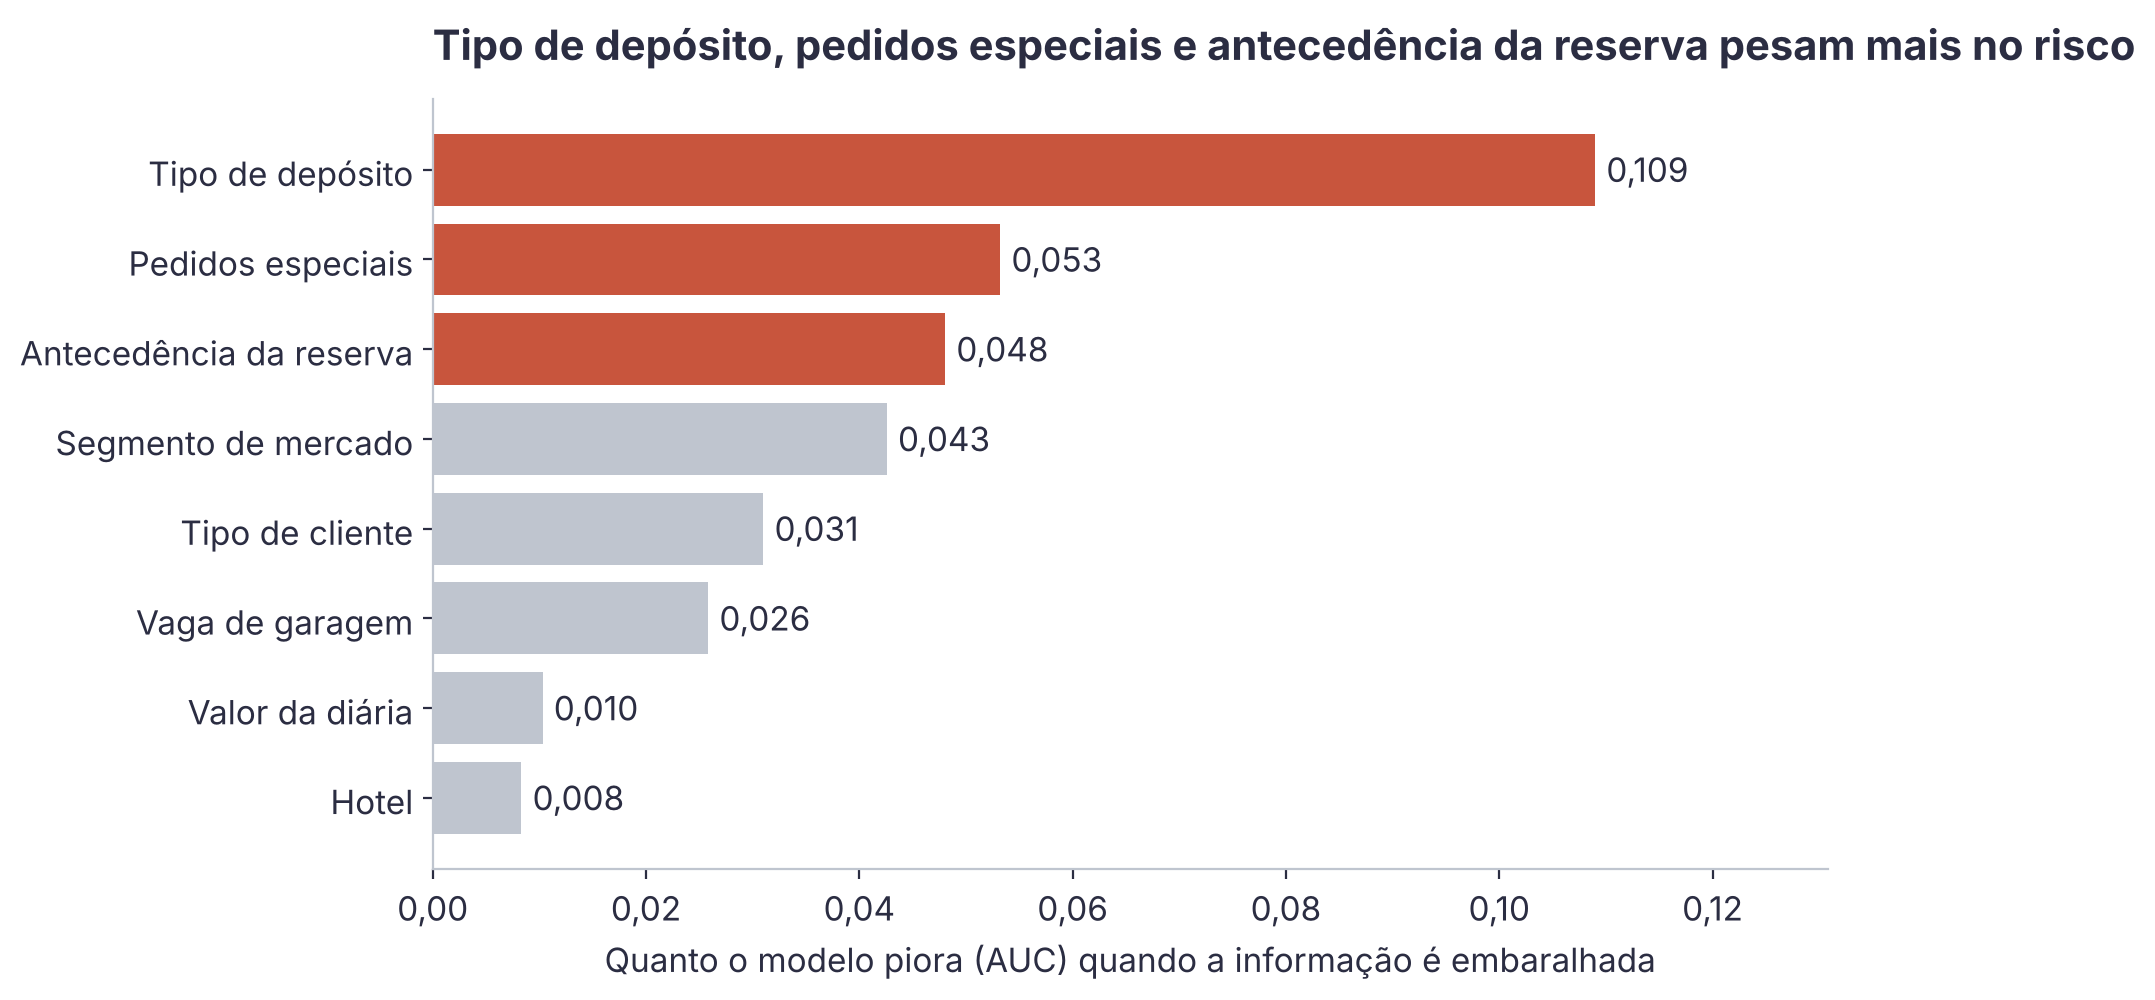

In [20]:
ordem = top8.iloc[::-1]
cores = [CORES["destaque"] if i >= len(ordem) - 3 else CORES["neutro"] for i in range(len(ordem))]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(ordem["nome"], ordem["piora_media_auc"], color=cores)
ax.bar_label(barras, labels=[br(v, 3) for v in ordem["piora_media_auc"]], padding=4)
ax.set_xlabel("Quanto o modelo piora (AUC) quando a informação é embaralhada")
ax.set_xlim(0, ordem["piora_media_auc"].max() * 1.2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 2)))
tres = top8["nome"].head(3).str.lower().tolist()
ax.set_title(f"{tres[0].capitalize()}, {tres[1]} e {tres[2]} pesam mais no risco")
salvar_figura(fig, "03_fatores_de_risco")
plt.show()

**Leitura:** os fatores que o modelo considera mais importantes **fazem sentido para quem
trabalha em hotel**, o que aumenta a confiança nele: tipo de depósito, antecedência, sinais
de compromisso do hóspede (pedidos especiais, vaga de garagem) e o canal e tipo da reserva.
Já o país do hóspede, que ficou de fora de propósito (decisão D5), não fez falta.

> **Atenção ao depósito "não reembolsável":** essas reservas cancelam quase sempre, o que
> contraria a intuição. A hipótese mais provável é que sejam reservas em bloco de operadoras e
> grupos, liberadas depois. **Isso é um achado para o hotel investigar**, não uma conclusão.
> O modelo usa o padrão porque ele se repete em 2017, mas, se a forma de registrar esse
> depósito mudar, o modelo precisa ser revisto.

## 9. O modelo atingiu o critério de sucesso?

O critério foi definido **antes de modelar** (issue #1). O modelo é considerado **útil para o
hotel** se, nas reservas de 2017:

1. acertar **mais do que a regra do gerente**; **e**
2. na faixa de **alto risco**, **pelo menos 7 de cada 10 reservas** realmente cancelarem.

In [21]:
criterio_1 = bool(m["f1"] > rg["f1"])
taxa_alto = float(alto["taxa_real_cancelamento"])
criterio_2 = bool(taxa_alto >= 0.70)

criterio = pd.DataFrame(
    [
        {
            "criterio": "1. Acerta mais do que a regra do gerente (nota F1 em 2017)",
            "meta": f"> {br(rg['f1'], 2)}",
            "resultado": br(m["f1"], 2),
            "atingiu": "Sim" if criterio_1 else "Não",
        },
        {
            "criterio": "2. Na faixa alta, pelo menos 7 de cada 10 cancelam",
            "meta": "≥ 70%",
            "resultado": pct(taxa_alto),
            "atingiu": "Sim" if criterio_2 else "Não",
        },
    ]
)
salvar_tabela(criterio, "03_criterio_de_sucesso")
display(criterio)
print("Critério de sucesso atingido:", "SIM" if (criterio_1 and criterio_2) else "NÃO")

,criterio,meta,resultado,atingiu
0,1. Acerta mais do que a regra do gerente (nota...,"> 0,58","0,67",Sim
1,"2. Na faixa alta, pelo menos 7 de cada 10 canc...",≥ 70%,"81,2%",Sim


Critério de sucesso atingido: SIM


## 10. Revisão do processo

Antes do veredito, conferimos se o trabalho foi feito de forma honesta:

1. **O modelo "decorou"?** Se o modelo tivesse só decorado as reservas antigas, a nota nos
   simulados (2015–2016) seria muito maior que a nota na prova final (2017).
2. **Alguma coluna proibida escapou?** Conferimos de novo, direto no modelo treinado.
3. **O teste foi usado uma única vez?** Sim: modelo e limiar foram escolhidos só com o treino
   (seções 4 e 5); o teste só entrou na seção 6.

In [22]:
revisao = pd.DataFrame(
    {
        "simulados no treino (2015–2016)": escolhido_cv[["precisao", "cobertura_recall", "f1", "auc"]],
        "prova final (2017)": m[["precisao", "cobertura_recall", "f1", "auc"]],
    }
)
revisao["diferença"] = revisao["prova final (2017)"] - revisao["simulados no treino (2015–2016)"]
display(revisao.round(3))

colunas_usadas = set(modelo_escolhido.named_steps["preparo"].feature_names_in_)
assert colunas_usadas == set(ATRIBUTOS) and not colunas_usadas & set(PROIBIDAS)
print(f"Colunas que o modelo treinado recebeu: {len(colunas_usadas)} — nenhuma proibida.")

,simulados no treino (2015–2016),prova final (2017),diferença
precisao,0.902,0.740,-0.163
cobertura_recall,0.709,0.617,-0.092
f1,0.794,0.673,-0.121
auc,0.930,0.840,-0.089


Colunas que o modelo treinado recebeu: 24 — nenhuma proibida.


**Leitura:** a nota na prova final é **menor** do que nos simulados. Isso era esperado e tem
duas explicações simples:

- **2017 é diferente de 2015–2016:** a taxa de cancelamento subiu (de 36% para 39%) e os
  hábitos de quem reserva mudam de um ano para outro. O modelo nunca viu esse ano.
- **Nos simulados, reservas de grupo quase iguais caem dos dois lados** (estudo e teste), o
  que deixa a nota dos simulados um pouco otimista. Foi exatamente por isso que a prova final
  usa um ano que o modelo nunca viu (decisão D2): **a nota de 2017 é a que vale**.

Mesmo com essa queda, o modelo continua acima da regra do gerente na nota F1.

**Ponto de atenção (sem maquiar):** em 2017 o modelo **avisa um pouco menos** cancelamentos
que a regra do gerente (cobertura 6 × 7 em cada 10), mas **erra muito menos** nos avisos
(precisão 7 × 5 em cada 10). Baixando o limiar, o modelo pega mais cancelamentos, em troca de
mais alarmes falsos.

### Limitações (o que o modelo não sabe)

- **Dados de 2015 a 2017:** o comportamento de quem reserva mudou depois disso (pandemia,
  mais reservas por aplicativo, novas políticas de cancelamento grátis). Antes de usar, o
  modelo precisa ser **treinado de novo com dados recentes** do próprio hotel.
- **Só dois hotéis em Portugal:** não dá para garantir que vale para outros hotéis.
- **Sem informação de fora:** o modelo não sabe o preço da concorrência, o clima, eventos na
  cidade, nem se o hóspede achou uma oferta melhor, que são motivos comuns de cancelamento.
- **Depósito "não reembolsável":** pesa muito no modelo, mas o padrão é estranho (seção 8).
  Se for um problema de registro e o hotel corrigir, o modelo precisa ser revisto.

## 11. Veredito

In [23]:
f_alto = faixas.set_index("faixa_risco").loc["Alto"]
print("O MODELO ATINGIU O CRITÉRIO DE SUCESSO?", "SIM" if (criterio_1 and criterio_2) else "NÃO")
print()
print(f"- Supera a regra do gerente: nota F1 {br(m['f1'], 2)} contra {br(rg['f1'], 2)} em 2017.")
print(f"- Na faixa de alto risco, {pct(taxa_alto, 0)} das reservas cancelaram ({em_10(taxa_alto)}).")
print(f"- Essa faixa reúne {pct(f_alto['pct_das_reservas'], 0)} das reservas e {pct(f_alto['pct_dos_cancelamentos'], 0)} de todos os cancelamentos.")

O MODELO ATINGIU O CRITÉRIO DE SUCESSO? SIM

- Supera a regra do gerente: nota F1 0,67 contra 0,58 em 2017.
- Na faixa de alto risco, 81% das reservas cancelaram (8 em cada 10).
- Essa faixa reúne 23% das reservas e 48% de todos os cancelamentos.


**Em linguagem simples:** **sim, o modelo atinge o critério de sucesso**:

- ele **atinge os dois critérios** definidos antes de começar;
- ele aponta um grupo **pequeno e bem definido** de reservas (a faixa alta, menos de 1 em cada
  4) em que 8 de cada 10 realmente cancelam.

**Ressalvas técnicas:** o modelo precisa ser treinado de novo com dados recentes antes de ser
usado, e o padrão do depósito "não reembolsável" ainda precisa ser esclarecido (notebook 04).

## 12. Arquivo para a implantação (issue #5)

Salvamos, para cada reserva de 2017, a chance de cancelamento e a faixa de risco. É a base
que o Gabriel usa na implantação e na apresentação.

In [24]:
COLUNAS_ENTREGA = [
    "hotel", "data_chegada", "antecedencia_dias", "segmento_mercado", "tipo_deposito",
    "diaria_media", "total_noites", "receita_estimada", "probabilidade_cancelamento",
    "faixa_risco", "cancelada",
]
entrega = teste_risco[COLUNAS_ENTREGA].copy()
entrega["data_chegada"] = entrega["data_chegada"].dt.strftime("%Y-%m-%d")
entrega["faixa_risco"] = entrega["faixa_risco"].astype(str)
caminho = salvar_tabela(entrega, "03_reservas_teste_com_risco")

assert len(entrega) == len(teste) and entrega["probabilidade_cancelamento"].between(0, 1).all()
print(f"Salvo: {caminho.relative_to(RAIZ)} ({br(len(entrega))} reservas)")
entrega.head()

Salvo: reports/tables/03_reservas_teste_com_risco.csv (40.619 reservas)


,hotel,data_chegada,antecedencia_dias,segmento_mercado,tipo_deposito,diaria_media,total_noites,receita_estimada,probabilidade_cancelamento,faixa_risco,cancelada
0,Resort,2017-01-01,74,Agência online,Sem depósito,57.60,1,57.60,0.456,Médio,1
1,Resort,2017-01-01,62,Agência online,Sem depósito,51.50,4,206.00,0.352,Médio,1
2,Resort,2017-01-01,62,Agência online,Sem depósito,51.50,4,206.00,0.352,Médio,1
3,Resort,2017-01-01,62,Agência online,Sem depósito,51.50,4,206.00,0.352,Médio,1
4,Resort,2017-01-01,71,Agência online,Sem depósito,32.22,4,128.88,0.392,Médio,1


## Resumo para a apresentação (2 minutos)

1. **A pergunta:** dá para saber, **antes da chegada**, quem vai cancelar?
2. **Como:** o modelo aprendeu com as reservas de 2015–2016 e foi testado em 2017, um ano que
   ele nunca viu.
3. **Resultado principal:** o gráfico das **faixas de risco** (`03_faixas_de_risco.png`): na
   faixa alta, 8 em cada 10 reservas cancelam; na faixa baixa, só 2 em cada 10.
4. **O que mais pesa:** tipo de depósito, pedidos especiais e antecedência.
5. **Veredito:** atinge os dois critérios de sucesso definidos antes de modelar.